# 07 — Tiki Integrated Analysis

Pipeline: Load → Validation → Preprocessing → IQR → RFM → EDA →
UK vs Tiki VN → Recommendations.

Tiki transactions in this analysis come only from verified purchase
reviews: one review is treated as one purchase. This sample does not
represent every Tiki order or customer. Tiki and UCI remain separate
datasets; results are compared side by side.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "data_processor.py").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository or notebooks/.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_TIKI = ROOT / "data" / "raw" / "tiki"
PROCESSED = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"

print("Repository:", ROOT)

Repository: d:\Project\pds301m-ecommerce-analytics


## 1. Load and validate raw Tiki data

In [2]:
products_path = RAW_TIKI / "all_products.json"
reviews_path = RAW_TIKI / "all_reviews.json"

assert products_path.is_file(), f"Missing {products_path}; copy it from Google Drive."
assert reviews_path.is_file(), f"Missing {reviews_path}; copy it from Google Drive."

with products_path.open(encoding="utf-8") as file:
    raw_products = json.load(file)
with reviews_path.open(encoding="utf-8") as file:
    raw_reviews = json.load(file)

assert isinstance(raw_products, list) and raw_products
assert isinstance(raw_reviews, list) and raw_reviews
assert all(isinstance(item, dict) for item in raw_products)
assert all(isinstance(item, dict) for item in raw_reviews)
assert len({item["id"] for item in raw_products}) == len(raw_products)

print("Raw products:", len(raw_products))
print("Raw reviews:", len(raw_reviews))

Raw products: 2100
Raw reviews: 5031


## 2. Preprocess verified purchase reviews

In [3]:
from src.data_processor import TikiDataProcessor

processor = TikiDataProcessor(RAW_TIKI)
processor.load_data()
processor.clean_data(deduplicate=True, fill_guest=True)
processor.engineer_features()

cleaned_path = PROCESSED / "cleaned_tiki.csv"
cancelled_path = PROCESSED / "cancelled_tiki.csv"
PROCESSED.mkdir(parents=True, exist_ok=True)

if not cleaned_path.exists():
    processor.df_valid.to_csv(cleaned_path, index=False)
if not cancelled_path.exists():
    processor.df_cancelled.to_csv(cancelled_path, index=False)

cleaned = pd.read_csv(
    cleaned_path,
    dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"},
)
cleaned["InvoiceDate"] = pd.to_datetime(cleaned["InvoiceDate"], errors="raise")

pd.testing.assert_frame_equal(
    processor.df_valid.sort_values("InvoiceNo").reset_index(drop=True),
    cleaned.sort_values("InvoiceNo").reset_index(drop=True),
    check_dtype=False,
)
required = {
    "InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate",
    "UnitPrice", "CustomerID", "Country", "Revenue", "YearMonth",
}
assert required == set(cleaned.columns)
assert len(cleaned) == processor.audit_stats["valid_rows"]
assert cleaned["InvoiceNo"].is_unique
assert not cleaned[list(required)].isna().any().any()
assert cleaned["Quantity"].eq(1).all()
assert cleaned["Country"].eq("Vietnam").all()
assert np.allclose(cleaned["Revenue"], cleaned["Quantity"] * cleaned["UnitPrice"])
assert cleaned["YearMonth"].eq(cleaned["InvoiceDate"].dt.strftime("%Y-%m")).all()

print("Verified reviews:", processor.audit_stats["verified_purchase_rows"])
print("Cleaned transactions:", len(cleaned))
print("Guest transactions:", processor.audit_stats["guest_rows"])
print("Revenue (VND):", f"{cleaned['Revenue'].sum():,.0f}")
display(cleaned.head(3))

Verified reviews: 5026
Cleaned transactions: 5026
Guest transactions: 0
Revenue (VND): 733,782,775


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth
0,TIKI_REV_20255890,279218500,Ship of Theseus - NXB Trẻ,1,2026-08-24 09:44:42,45000,30280853,Vietnam,45000,2026-08
1,TIKI_REV_20253464,279218500,Ship of Theseus - NXB Trẻ,1,2026-08-14 02:24:40,45000,5204311,Vietnam,45000,2026-08
2,TIKI_REV_20253463,279218500,Ship of Theseus - NXB Trẻ,1,2026-08-14 02:24:34,45000,5204311,Vietnam,45000,2026-08


## 3. Upper-tail IQR anomaly detection

Apply Q3 + 1.5 × IQR to order revenue and total quantity. Anomalies are
flagged, not removed from the analysis. Monetary values are in VND.
The reviewed purchases are a sample, not all orders on Tiki.


=== 2. HIGH-VALUE ANOMALY DETECTION (UPPER-TAIL IQR) ===
- Revenue: Q1=VND 73,600.00, Q3=VND 157,500.00, IQR=VND 83,900.00 -> Threshold Q3 + 1.5*IQR = VND 283,350.00
- Quantity: Q1=1.0, Q3=1.0, IQR=0.0 -> Threshold Q3 + 1.5*IQR =1.0
- Revenue anomaly orders:            241
- Quantity anomaly orders:           0
- Combined anomaly orders:           241
Orders: 5026
Revenue threshold (VND): 283350.0
Revenue anomalies: 241
Quantity anomalies: 0
Exported anomaly rows: 241


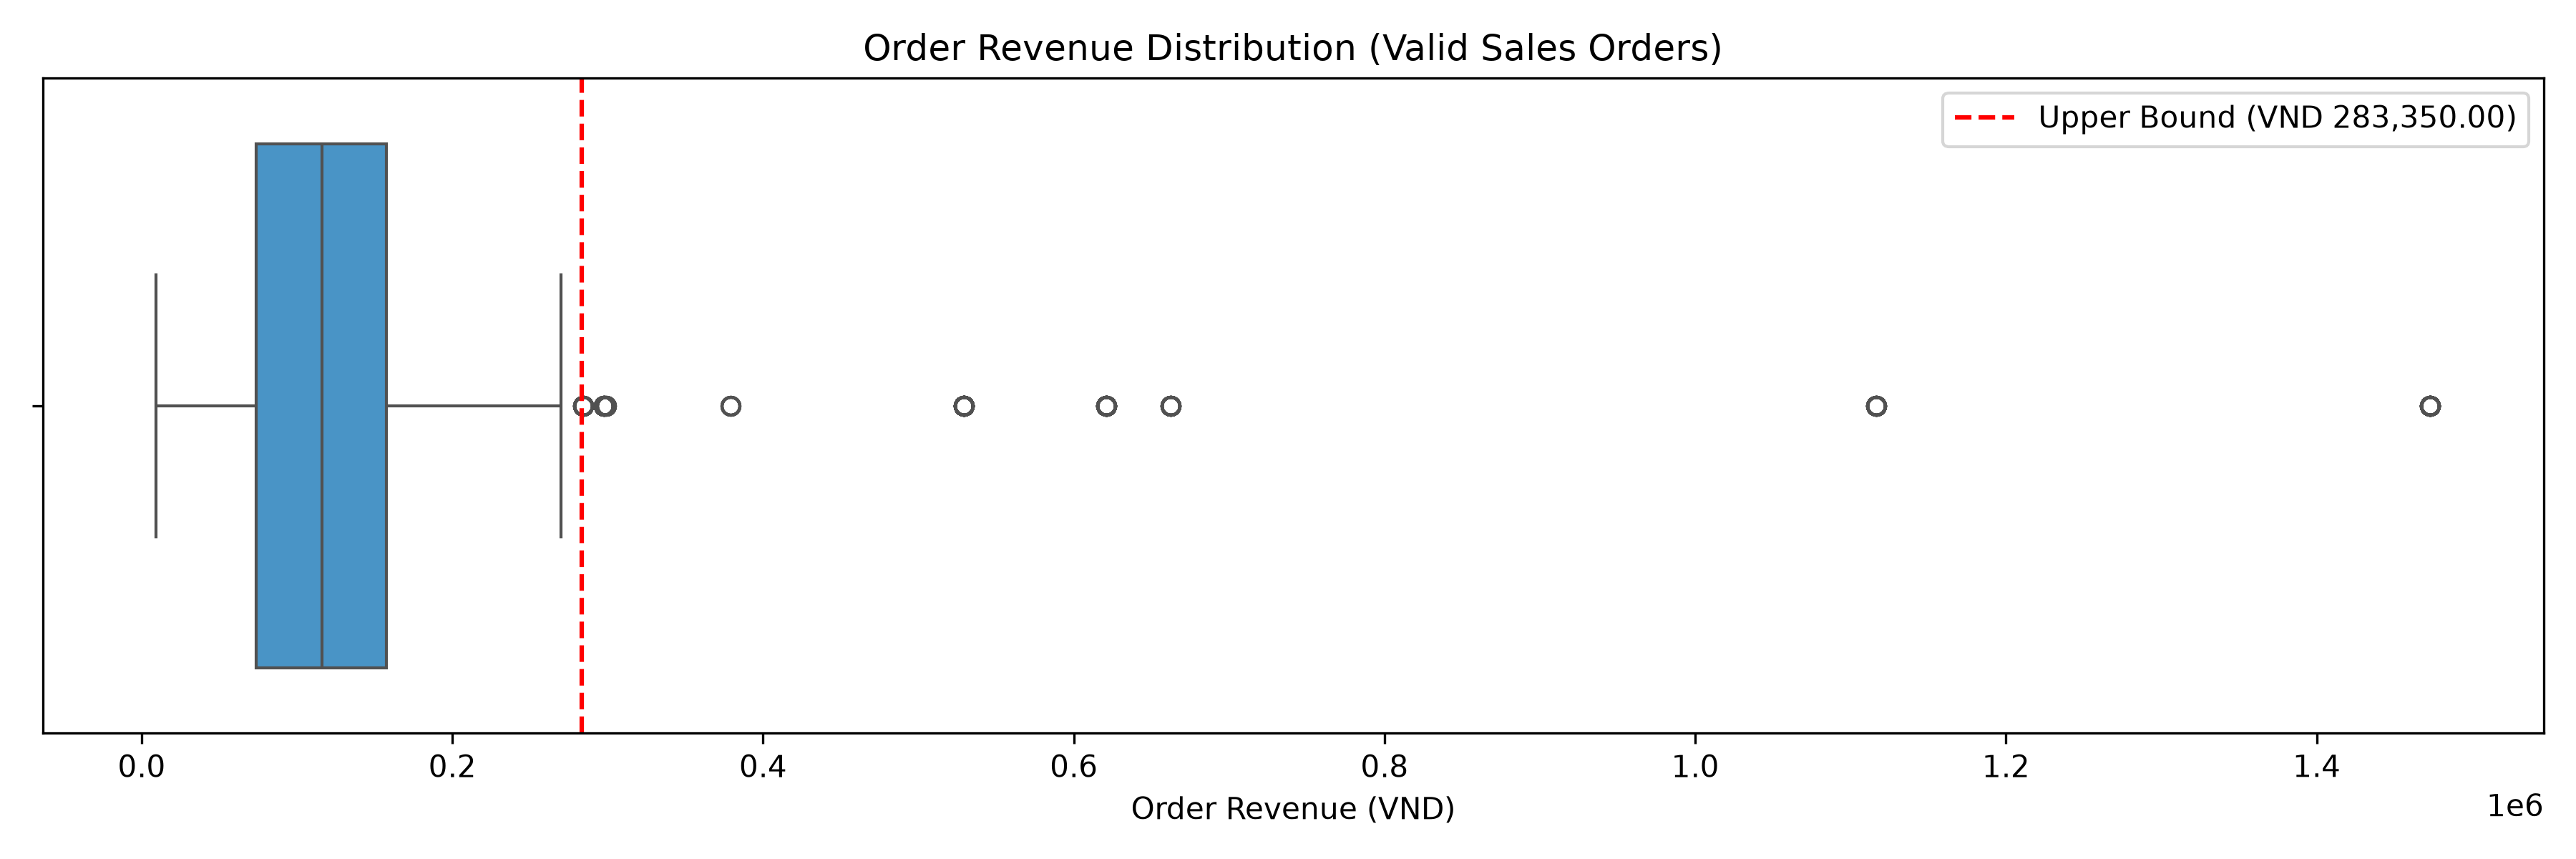

In [4]:
from IPython.display import Image
from src.anomaly_detector import OrderAnomalyDetector

anomaly_path = PROCESSED / "tiki_anomaly_orders.csv"
boxplot_path = CHARTS / "tiki_revenue_boxplot.png"

detector = OrderAnomalyDetector(df_valid=cleaned, currency_prefix="VND ")
orders = detector.detect_iqr_anomalies(
    output_csv_path=anomaly_path if not anomaly_path.exists() else None
)

assert len(orders) == cleaned["InvoiceNo"].nunique()
assert orders["IsAnomaly"].eq(
    orders["IsRevenueAnomaly"] | orders["IsQuantityAnomaly"]
).all()

flagged = orders.loc[orders["IsAnomaly"]].copy()
saved = pd.read_csv(anomaly_path, dtype={"InvoiceNo": "string"})

pd.testing.assert_frame_equal(
    flagged.sort_values("InvoiceNo").reset_index(drop=True),
    saved.sort_values("InvoiceNo").reset_index(drop=True),
    check_dtype=False,
)

detector.visualize_distribution(boxplot_path)

print("Orders:", len(orders))
print("Revenue threshold (VND):", detector.metrics["ub_rev"])
print("Revenue anomalies:", int(orders["IsRevenueAnomaly"].sum()))
print("Quantity anomalies:", int(orders["IsQuantityAnomaly"].sum()))
print("Exported anomaly rows:", len(saved))
display(Image(filename=str(boxplot_path), width=900))

## 4. RFM segmentation of reviewed customers

RFM is calculated only for identified customers with verified purchase
reviews. Guest is excluded. Scores use tie-safe percentile ranks and the
existing six segment rules. These segments do not represent all Tiki customers.

In [5]:
from src.feature_engineering import (
    CUSTOMER_SEGMENTS_COLUMNS,
    calculate_rfm,
    prepare_rfm_transactions,
)

segment_path = PROCESSED / "tiki_customer_segments.csv"
eligible = prepare_rfm_transactions(cleaned)
segments, rfm_metadata = calculate_rfm(cleaned, return_metadata=True)

assert segments.columns.tolist() == CUSTOMER_SEGMENTS_COLUMNS
assert segments["CustomerID"].is_unique
assert not segments["CustomerID"].eq("Guest").any()
assert segments[["R_score", "F_score", "M_score"]].apply(
    lambda column: column.between(1, 5).all()
).all()
assert np.isclose(segments["Monetary"].sum(), eligible["Revenue"].sum())

if not segment_path.exists():
    segments.to_csv(segment_path, index=False)

saved_segments = pd.read_csv(
    segment_path,
    dtype={"CustomerID": "string", "RFM_score": "string"},
)
for column in ["LastPurchaseDate", "ReferenceDate"]:
    saved_segments[column] = pd.to_datetime(saved_segments[column])

pd.testing.assert_frame_equal(
    segments.sort_values("CustomerID").reset_index(drop=True),
    saved_segments.sort_values("CustomerID").reset_index(drop=True),
    check_dtype=False,
)

print("Eligible transactions:", rfm_metadata["valid_transaction_rows"])
print("Customers:", rfm_metadata["customers"])
print("Reference date:", rfm_metadata["reference_date"])
print(segments["Segment"].value_counts())
display(segments.head(5))

Eligible transactions: 5026
Customers: 3809
Reference date: 2026-11-10 00:00:00
Segment
At Risk                1524
Potential Loyalists    1185
Others                  670
Champions               297
Loyal Customers         133
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,RFM_total,Segment,LastPurchaseDate,ReferenceDate
0,8485344,56,3,3348750,5,5,5,555,15,Champions,2026-09-15,2026-11-10
1,21923903,96,3,2255000,5,5,5,555,15,Champions,2026-08-06,2026-11-10
2,25755454,2,18,2107300,5,5,5,555,15,Champions,2026-11-08,2026-11-10
3,8337902,146,2,1631000,5,5,5,555,15,Champions,2026-06-17,2026-11-10
4,22981357,21,2,1629000,5,5,5,555,15,Champions,2026-10-20,2026-11-10


## 5. Tiki exploratory analysis

The price distribution uses review-derived transactions. The product ranking,
discount distribution, and correlations use the sampled product catalog.
Reported units sold come from the catalog, because the review scraper limits
the number of reviews collected per product.

Review-derived price observations: 5026
Ranked catalog products: 10
Catalog products with discount data: 2100
Rated products in correlation analysis: 1602
Tiki charts: 5


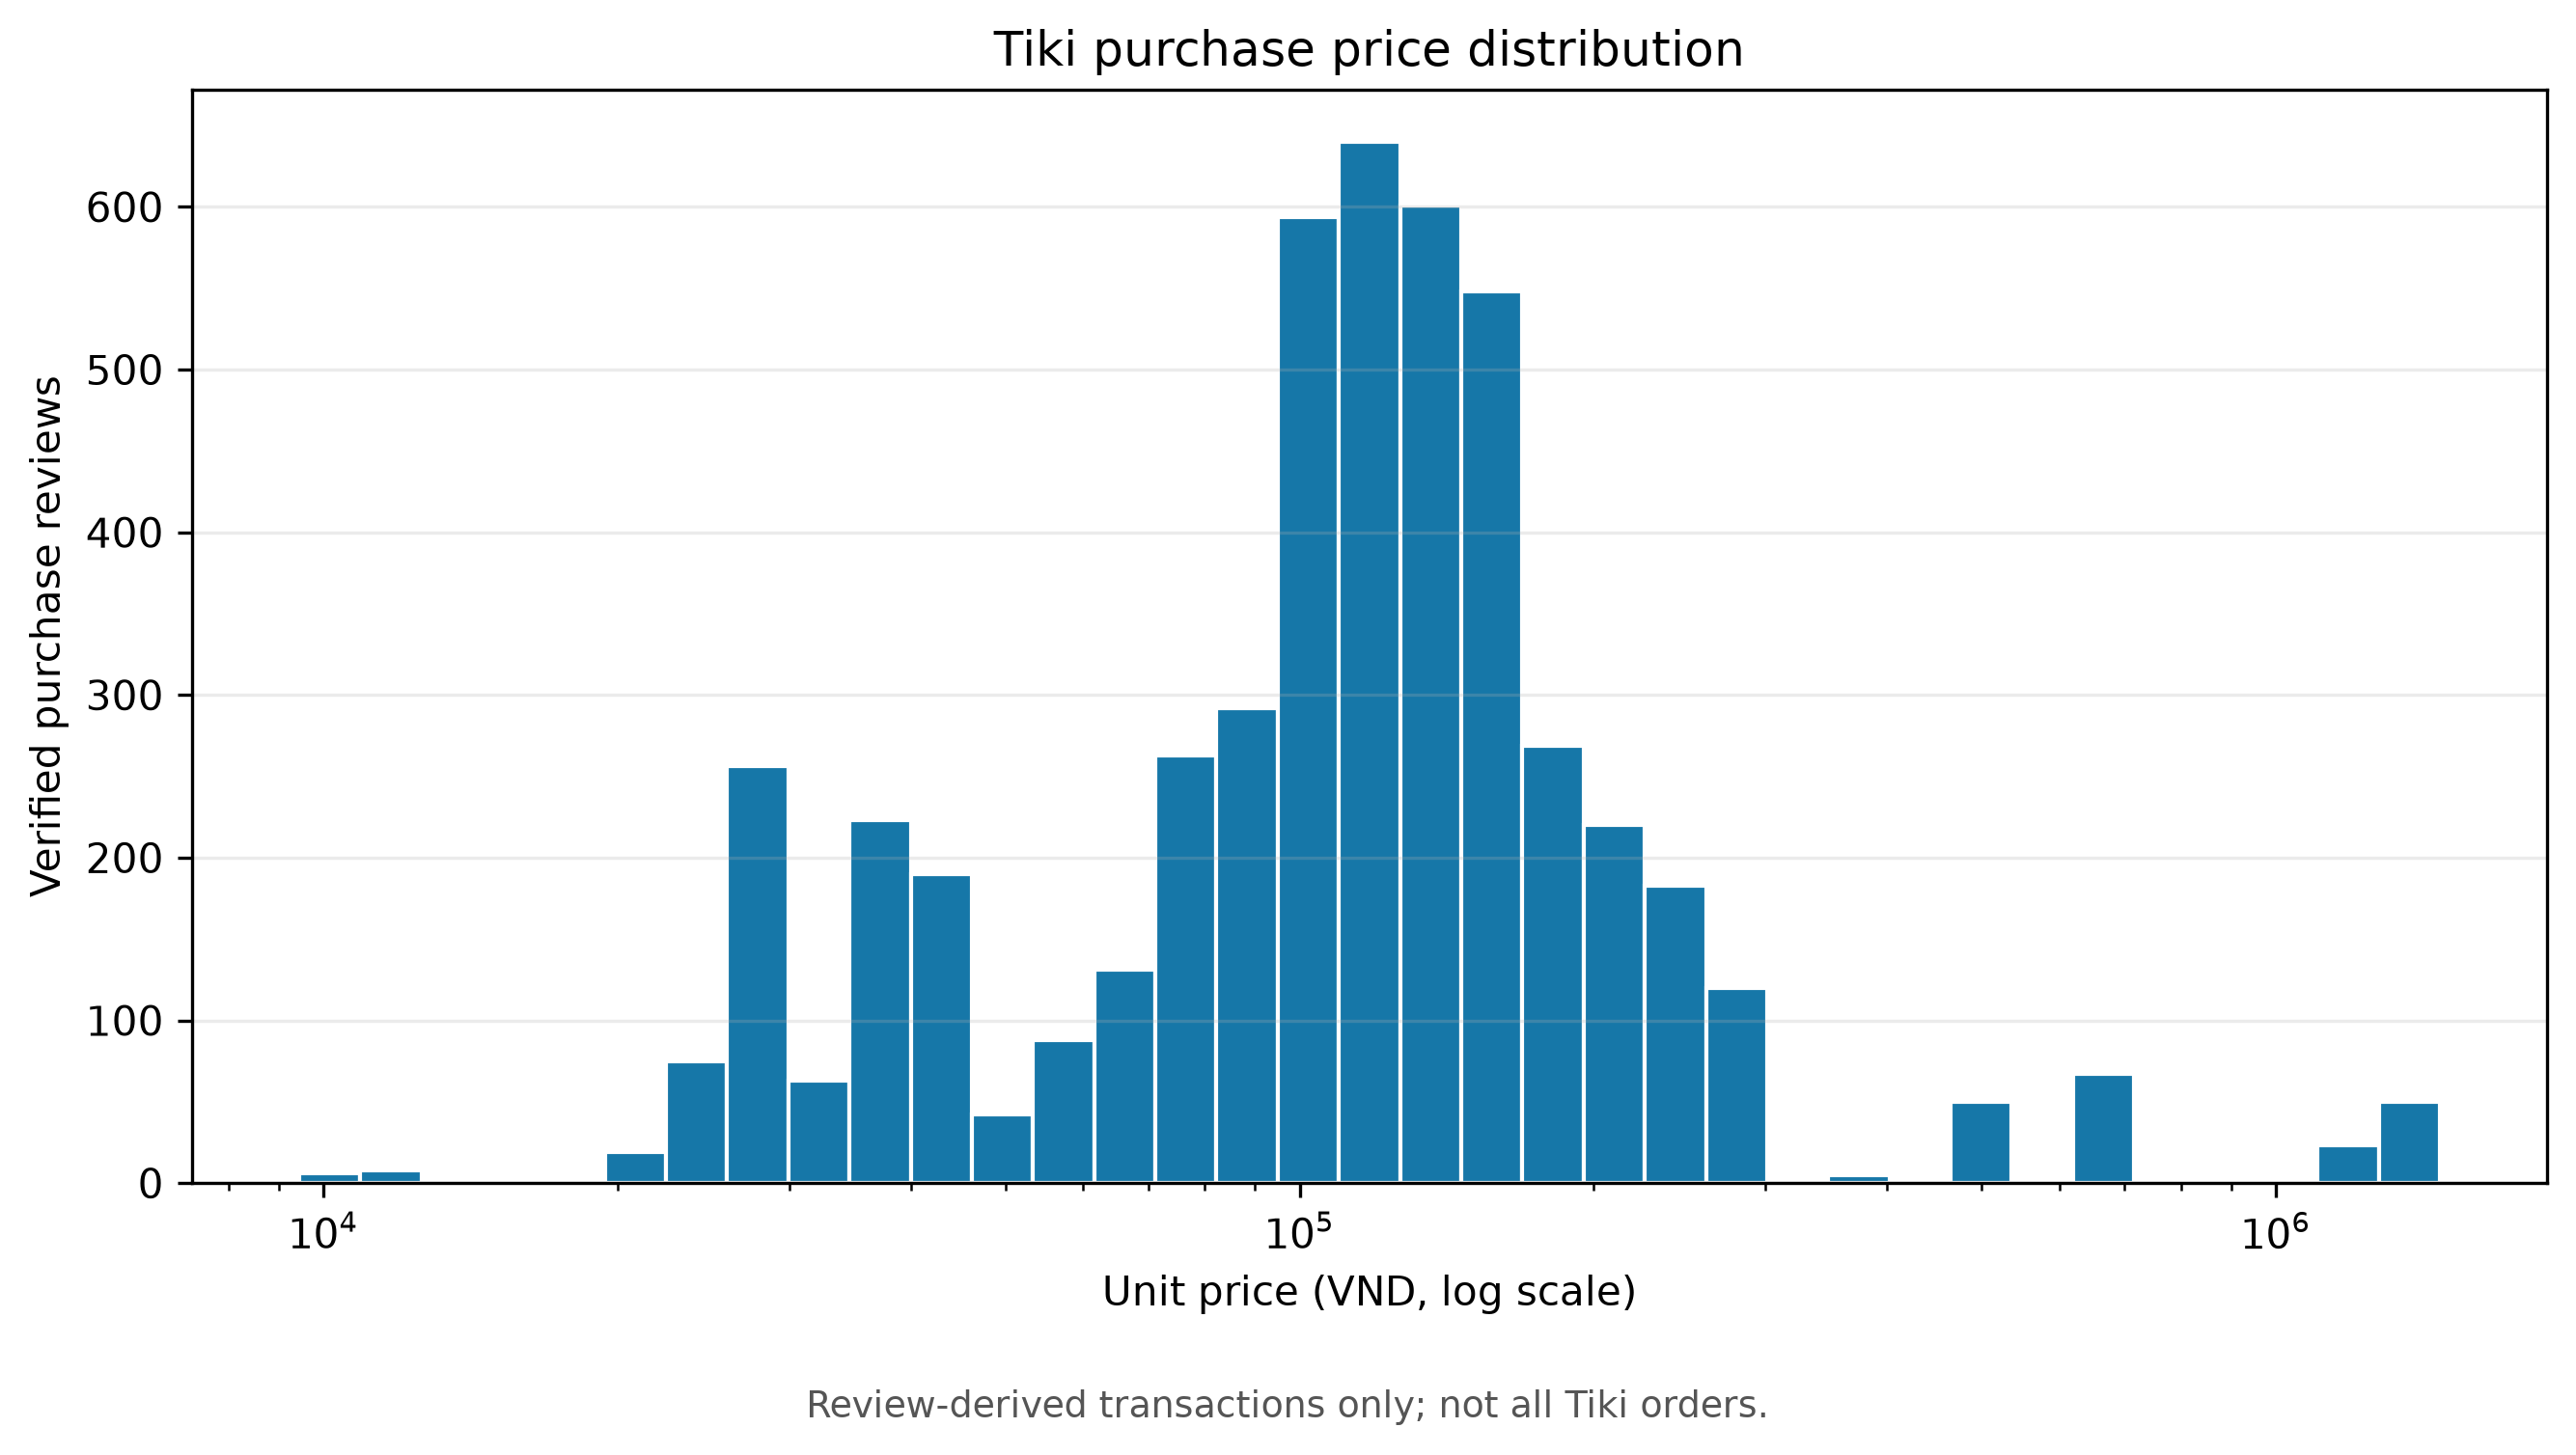

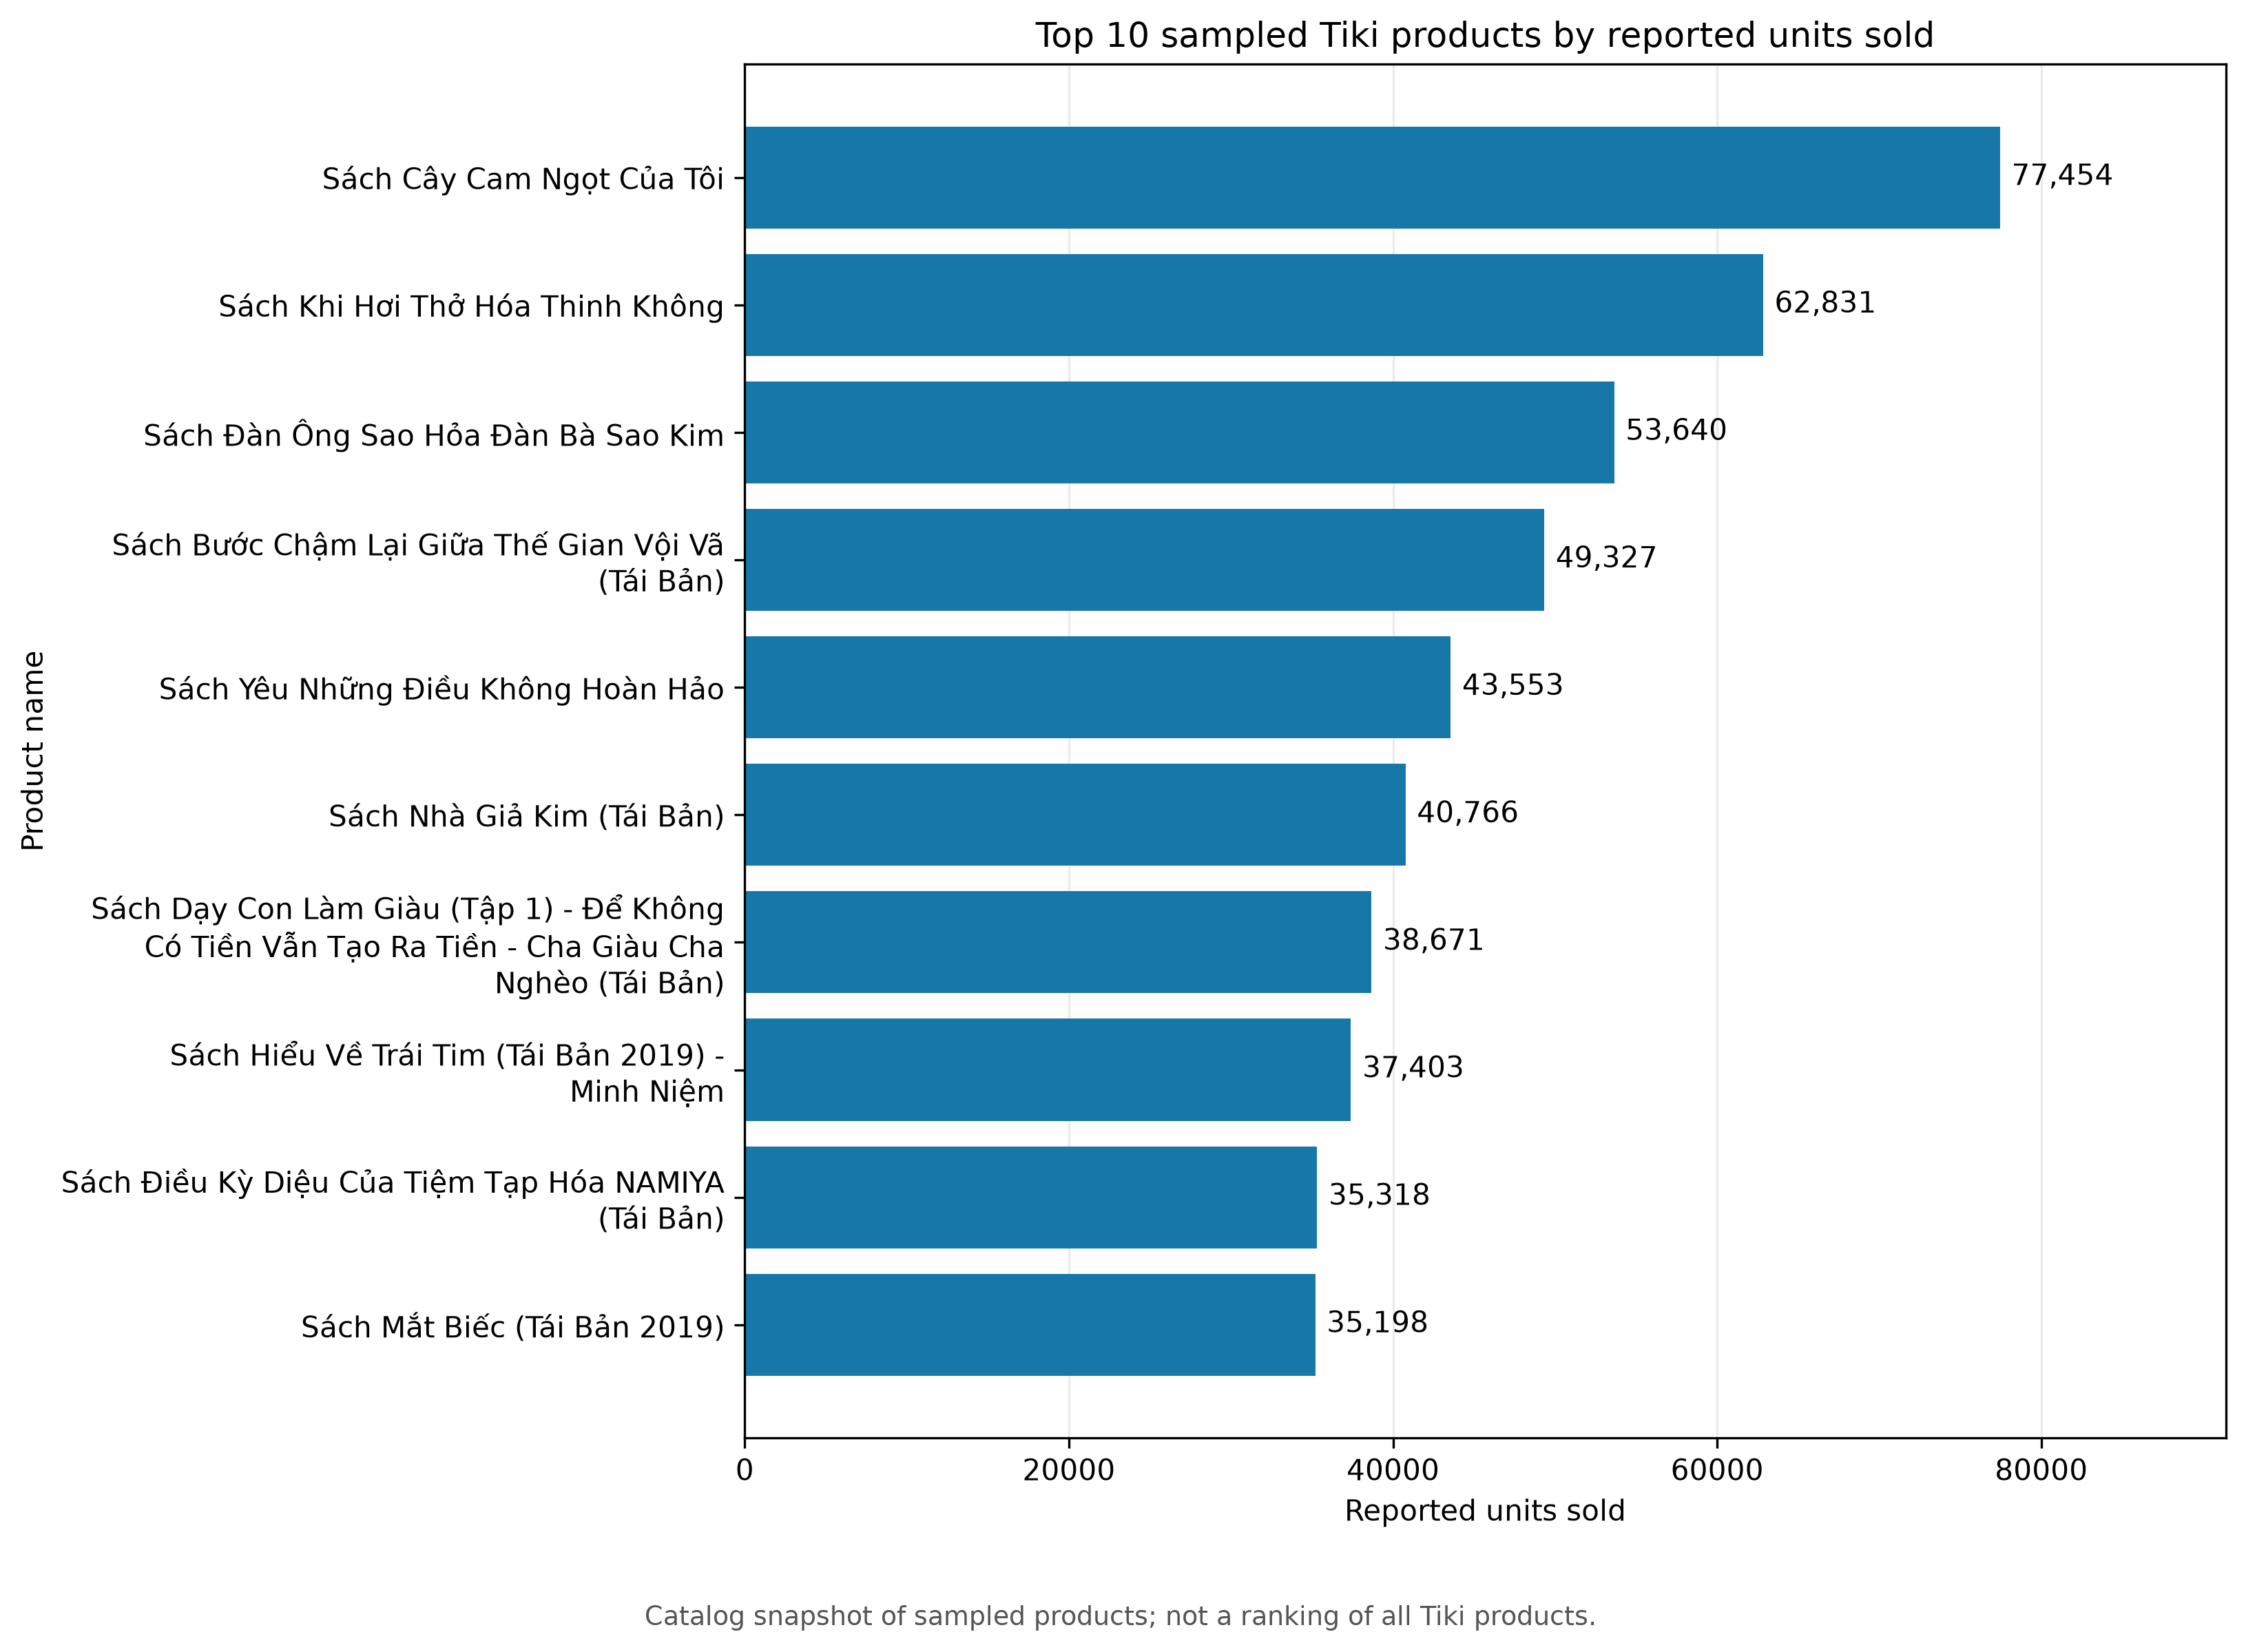

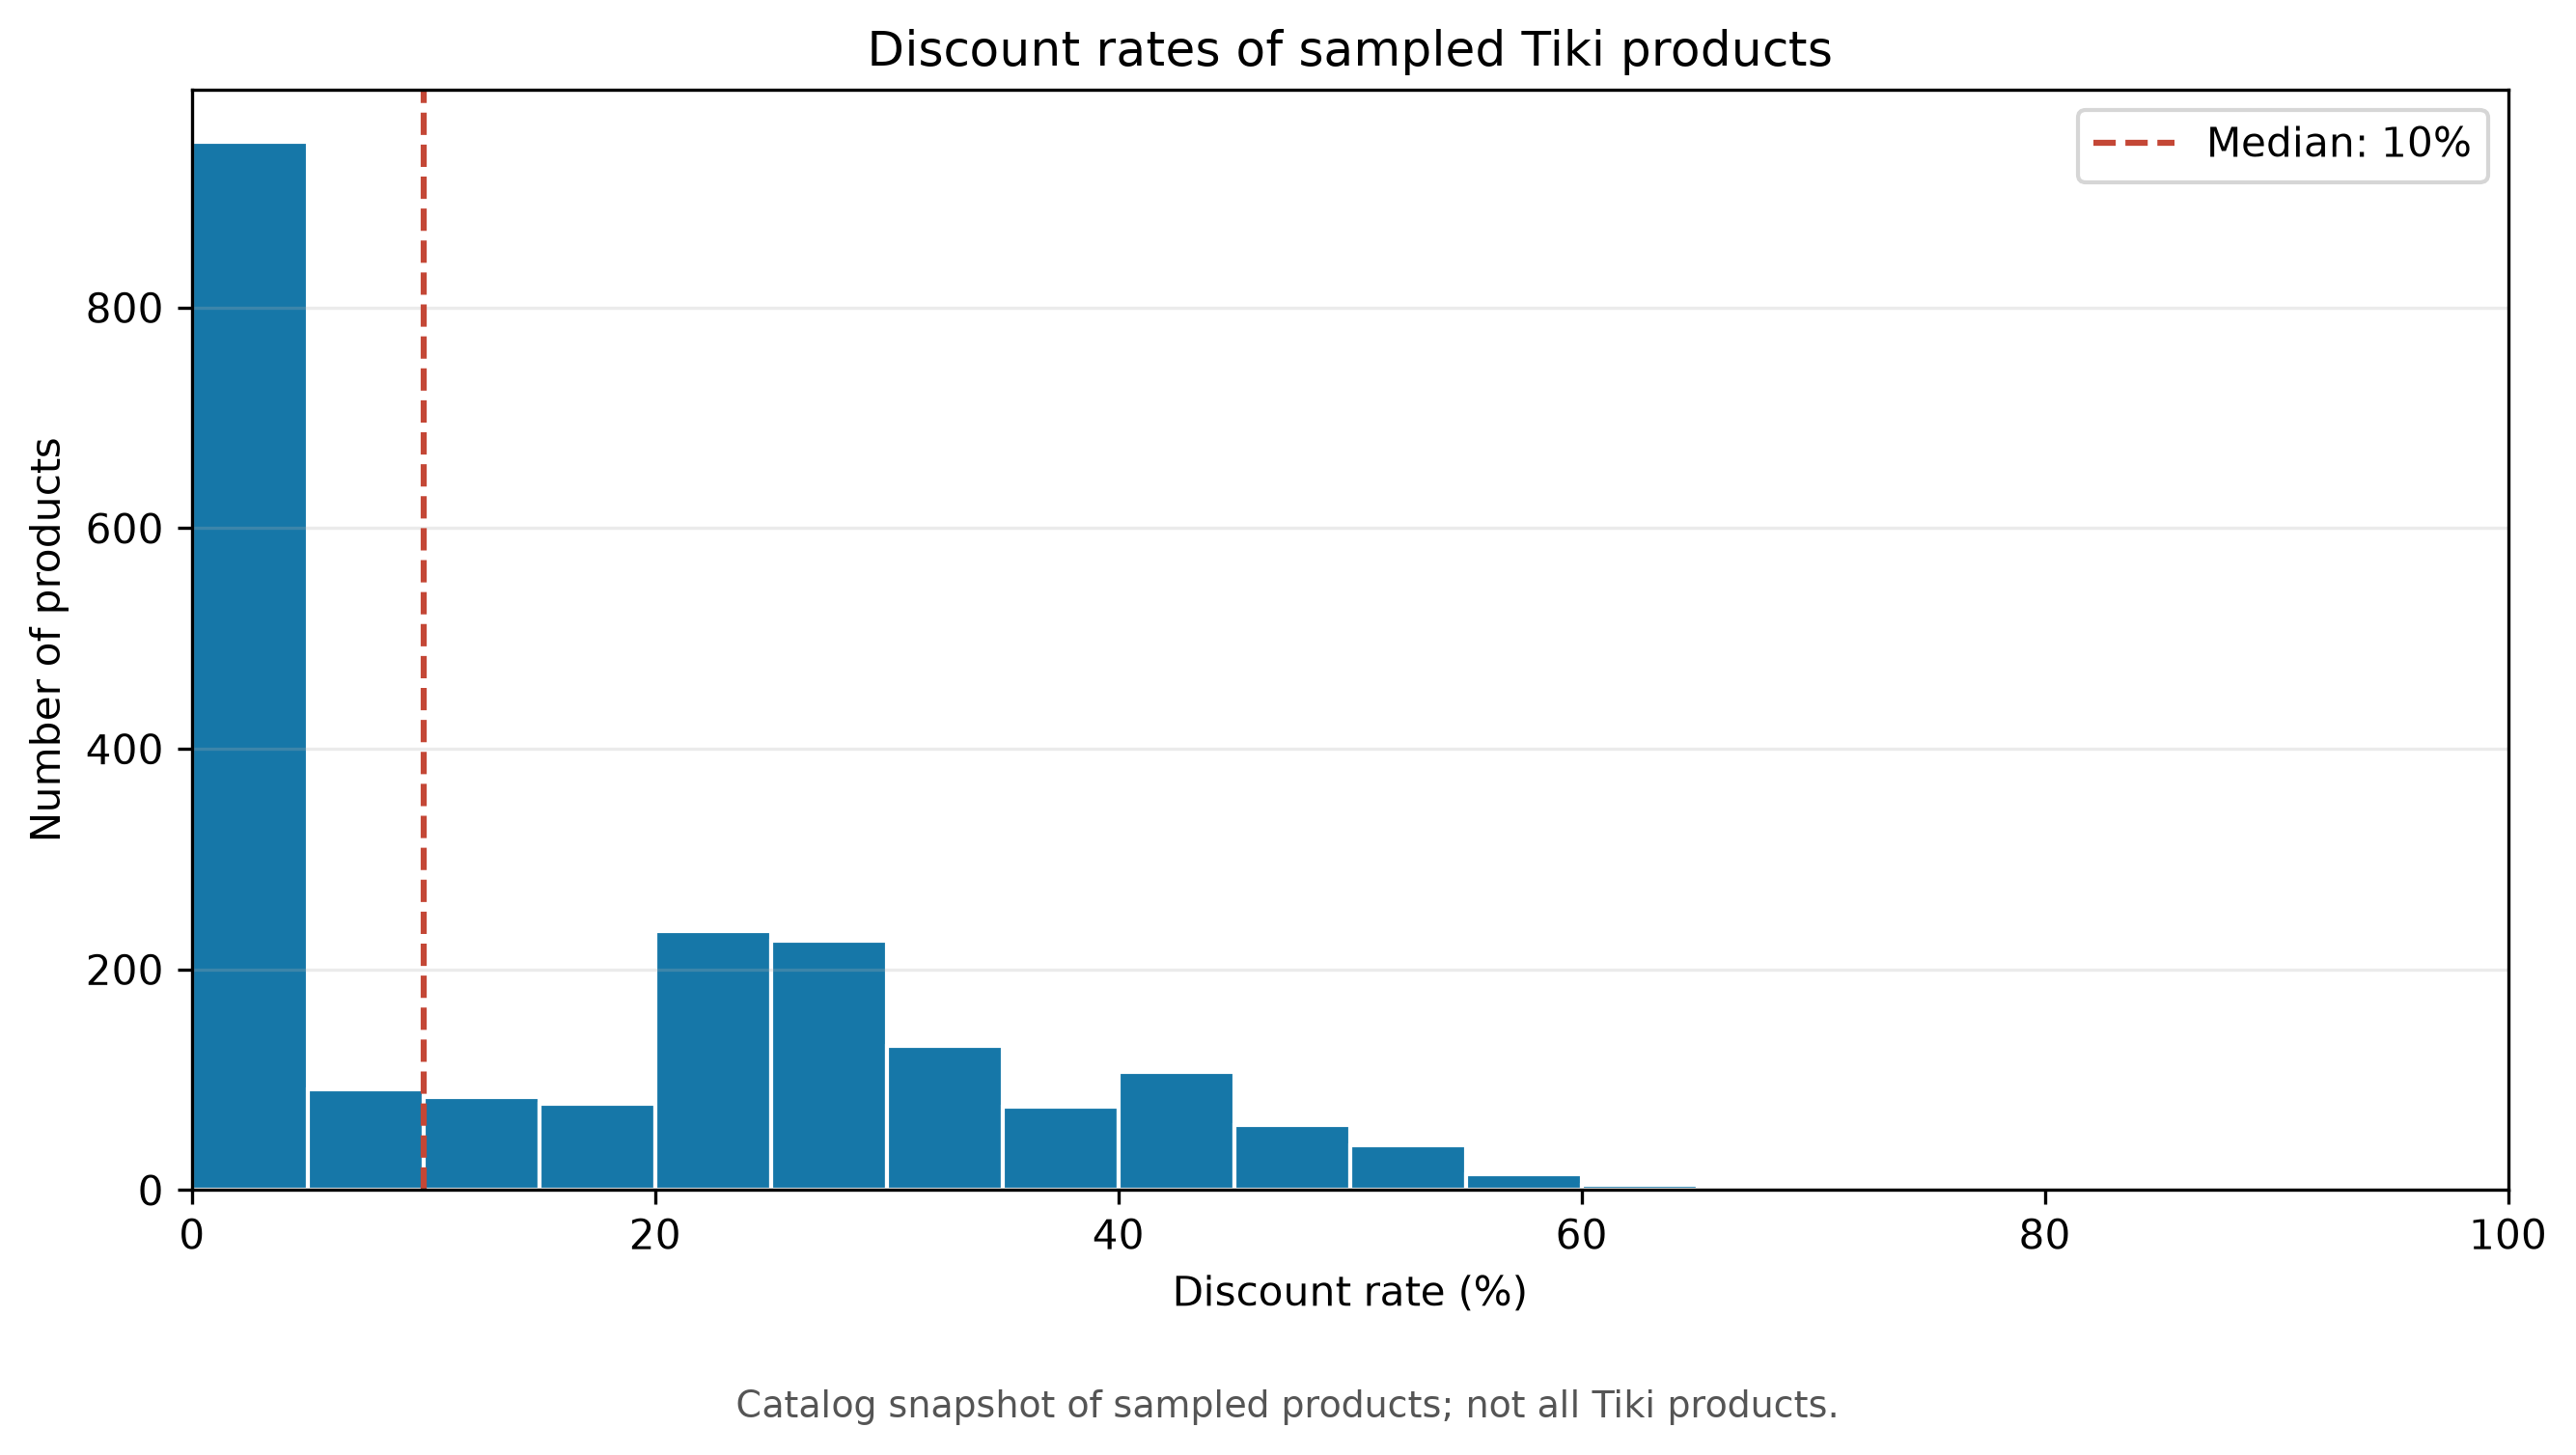

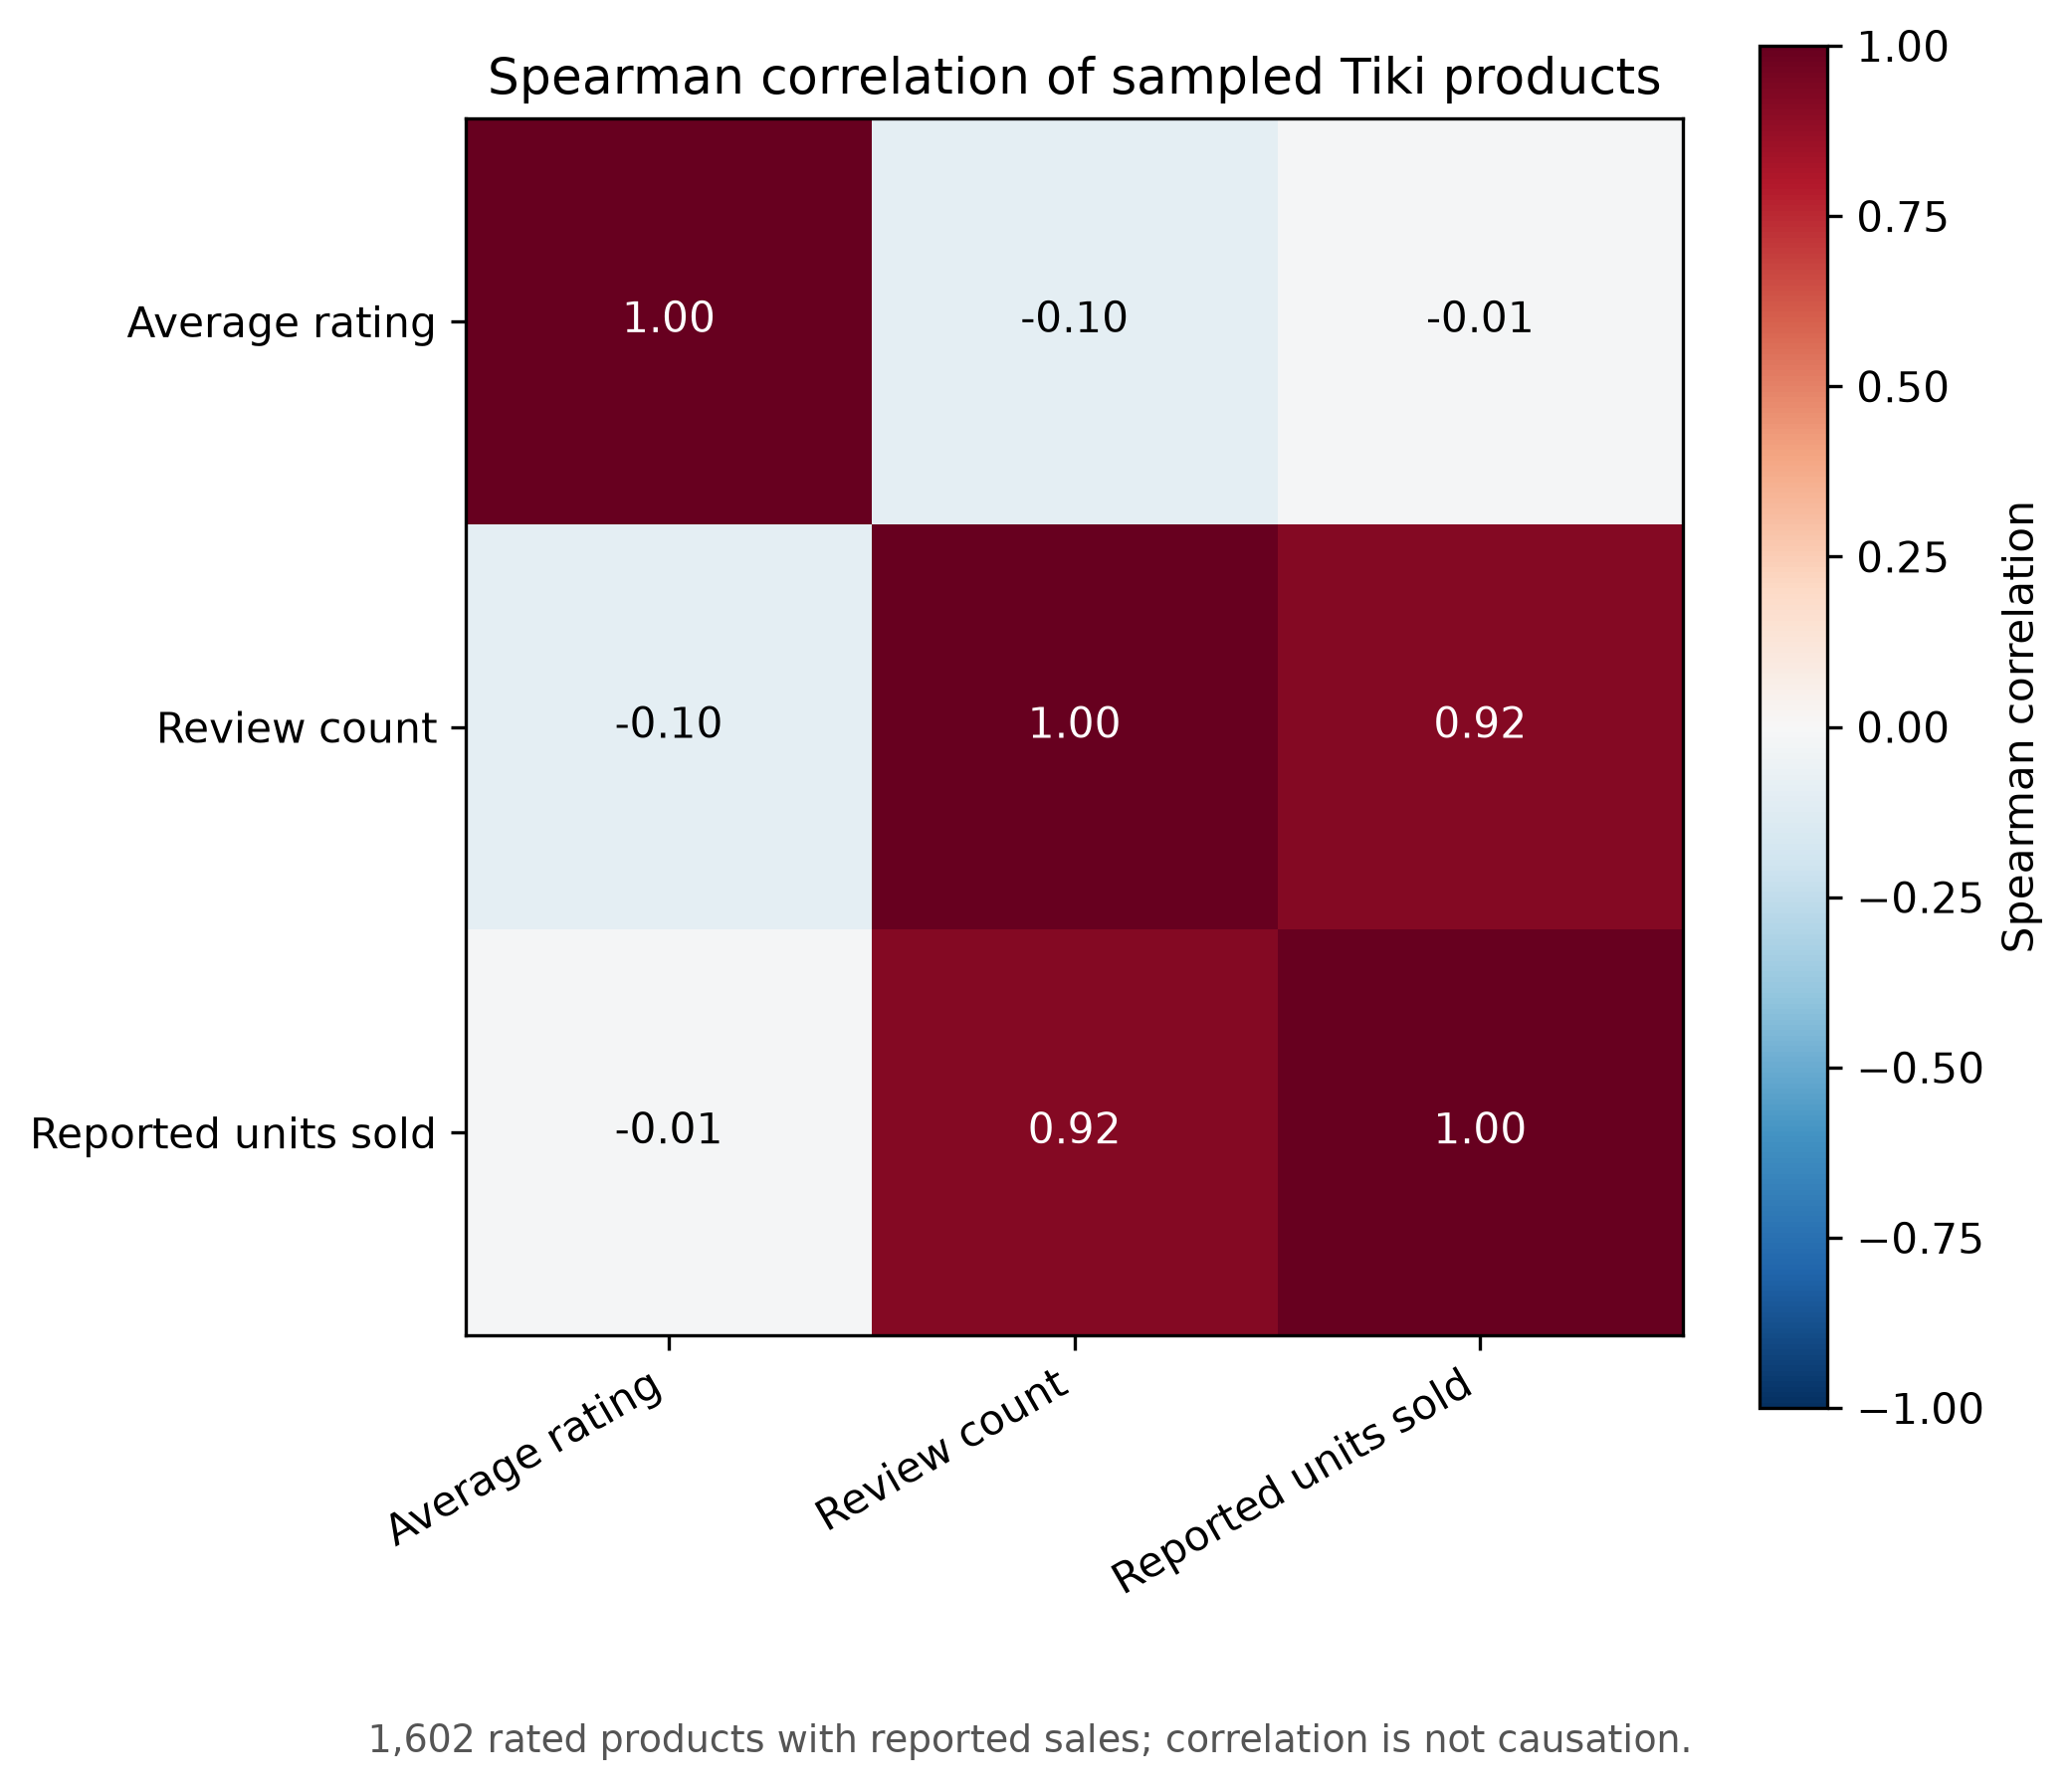

In [6]:
from src.tiki_eda import (
    plot_price_distribution,
    plot_top_products_sold,
    plot_discount_distribution,
    plot_product_correlations,
)

CHARTS.mkdir(parents=True, exist_ok=True)

eda_charts = [
    CHARTS / "tiki_price_distribution.png",
    CHARTS / "tiki_top_products_sold.png",
    CHARTS / "tiki_discount_distribution.png",
    CHARTS / "tiki_product_correlations.png",
]

price_count = plot_price_distribution(cleaned_path, eda_charts[0])
top_count = plot_top_products_sold(products_path, eda_charts[1])
discount_count = plot_discount_distribution(products_path, eda_charts[2])
correlation_count = plot_product_correlations(products_path, eda_charts[3])

all_charts = [boxplot_path, *eda_charts]
assert all(path.is_file() and path.stat().st_size > 0 for path in all_charts)
assert price_count == len(cleaned)
assert top_count == 10
assert discount_count == len(raw_products)

print("Review-derived price observations:", price_count)
print("Ranked catalog products:", top_count)
print("Catalog products with discount data:", discount_count)
print("Rated products in correlation analysis:", correlation_count)
print("Tiki charts:", len(all_charts))

for path in eda_charts:
    display(Image(filename=str(path), width=750))

## 6. UK UCI vs Tiki VN — side-by-side comparison

UCI UK contains invoice lines from 2010–2011. Tiki contains verified-review
purchase proxies collected from sampled products, with a review collection cap
per product. The datasets are analyzed separately and never joined.

Repeat-customer and anomaly percentages describe each observed sample only.
Revenue is not compared directly because UCI uses GBP and Tiki uses VND.

In [7]:
retail_path = PROCESSED / "cleaned_retail.csv"
assert retail_path.is_file(), f"Missing {retail_path}; copy it from Google Drive."

retail = pd.read_csv(
    retail_path,
    dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"},
    low_memory=False,
)
uk = retail.loc[retail["Country"].eq("United Kingdom")].copy()
uk["InvoiceDate"] = pd.to_datetime(uk["InvoiceDate"], errors="raise")
assert not uk.empty

uk_segments = calculate_rfm(uk)
uk_detector = OrderAnomalyDetector(df_valid=uk, currency_prefix="GBP ")
uk_orders = uk_detector.detect_iqr_anomalies()

comparison = pd.DataFrame({
    "UCI UK": [
        "Invoice line",
        f"{uk['InvoiceDate'].min():%Y-%m-%d} to {uk['InvoiceDate'].max():%Y-%m-%d}",
        len(uk),
        uk["InvoiceNo"].nunique(),
        uk["StockCode"].nunique(),
        len(uk_segments),
        f"{uk_segments['Frequency'].ge(2).mean():.1%}",
        f"{uk_orders['IsAnomaly'].mean():.1%}",
        "GBP",
    ],
    "Tiki VN": [
        "Verified review → purchase proxy",
        f"{cleaned['InvoiceDate'].min():%Y-%m-%d} to {cleaned['InvoiceDate'].max():%Y-%m-%d}",
        len(cleaned),
        len(orders),
        cleaned["StockCode"].nunique(),
        len(segments),
        f"{segments['Frequency'].ge(2).mean():.1%}",
        f"{orders['IsAnomaly'].mean():.1%}",
        "VND",
    ],
}, index=[
    "Observation unit",
    "Observed dates",
    "Rows",
    "Order IDs",
    "Product IDs",
    "Identified customers",
    "Customers with ≥2 observed orders",
    "Orders flagged by within-track IQR",
    "Currency",
])

segment_order = [
    "Champions", "Loyal Customers", "At Risk",
    "Potential Loyalists", "Hibernating", "Others",
]
segment_mix = pd.DataFrame({
    "UCI UK": uk_segments["Segment"].value_counts(normalize=True),
    "Tiki VN": segments["Segment"].value_counts(normalize=True),
}).reindex(segment_order).fillna(0)

display(comparison)
display(segment_mix.style.format("{:.1%}"))


=== 2. HIGH-VALUE ANOMALY DETECTION (UPPER-TAIL IQR) ===
- Revenue: Q1=GBP 147.06, Q3=GBP 465.31, IQR=GBP 318.25 -> Threshold Q3 + 1.5*IQR = GBP 942.70
- Quantity: Q1=67.0, Q3=283.0, IQR=216.0 -> Threshold Q3 + 1.5*IQR =607.0
- Revenue anomaly orders:            1,602
- Quantity anomaly orders:           1,272
- Combined anomaly orders:           1,942


,UCI UK,Tiki VN
Observation unit,Invoice line,Verified review → purchase proxy
Observed dates,2010-12-01 to 2011-12-09,2019-01-04 to 2026-11-09
Rows,479985,5026
Order IDs,18019,5026
Product IDs,3916,140
Identified customers,3920,3809
Customers with ≥2 observed orders,65.6%,13.5%
Orders flagged by within-track IQR,10.8%,4.8%
Currency,GBP,VND


,UCI UK,Tiki VN
Segment,,
Champions,21.1%,7.8%
Loyal Customers,8.5%,3.5%
At Risk,21.8%,40.0%
Potential Loyalists,11.3%,31.1%
Hibernating,18.5%,0.0%
Others,18.8%,17.6%


In [8]:
from IPython.display import Markdown

at_risk_count = int(segments["Segment"].eq("At Risk").sum())
potential_count = int(segments["Segment"].eq("Potential Loyalists").sum())
anomaly_count = int(orders["IsAnomaly"].sum())

display(Markdown(f"""
## 7. Findings, limitations and recommendations

### Findings

- The Tiki sample contains **{len(cleaned):,} verified-review purchase proxies**
  from **{len(segments):,} identified customers**.
- **{anomaly_count:,} observed orders** ({anomaly_count / len(orders):.1%})
  exceed an upper-tail IQR bound. They remain in the dataset with flags.
- Within the reviewed-customer sample, **{at_risk_count:,}** customers are
  classified *At Risk* and **{potential_count:,}** as *Potential Loyalists*.

### Interpretation limits

- One verified review is treated as one observed purchase, but the dataset
  does **not** contain every Tiki order or customer. Review collection was
  capped per product.
- `InvoiceDate` comes from **review creation time**, which may differ from
  purchase time. `UnitPrice` comes from the **catalog snapshot**, not the
  historical checkout price. Tiki Revenue and RFM Monetary are therefore
  **proxies**, not audited sales or customer spend.
- UCI UK invoice lines (2010–2011) and Tiki review proxies (2019–2026) have
  different coverage and observation units. Their percentages describe
  separate samples; GBP and VND revenue are not compared directly.

### Recommendations

1. Inspect the **{anomaly_count:,} flagged records** for data quality and
   unusually high catalog prices. An IQR flag alone does not imply fraud.
2. Use Tiki RFM segments to form **hypotheses about reviewed customers**.
   Validate them on full order histories before running customer campaigns.
3. Obtain purchase timestamps, checkout prices and broader order coverage;
   then rerun IQR, RFM and the UK–VN comparison on better matched data.
"""))


## 7. Findings, limitations and recommendations

### Findings

- The Tiki sample contains **5,026 verified-review purchase proxies**
  from **3,809 identified customers**.
- **241 observed orders** (4.8%)
  exceed an upper-tail IQR bound. They remain in the dataset with flags.
- Within the reviewed-customer sample, **1,524** customers are
  classified *At Risk* and **1,185** as *Potential Loyalists*.

### Interpretation limits

- One verified review is treated as one observed purchase, but the dataset
  does **not** contain every Tiki order or customer. Review collection was
  capped per product.
- `InvoiceDate` comes from **review creation time**, which may differ from
  purchase time. `UnitPrice` comes from the **catalog snapshot**, not the
  historical checkout price. Tiki Revenue and RFM Monetary are therefore
  **proxies**, not audited sales or customer spend.
- UCI UK invoice lines (2010–2011) and Tiki review proxies (2019–2026) have
  different coverage and observation units. Their percentages describe
  separate samples; GBP and VND revenue are not compared directly.

### Recommendations

1. Inspect the **241 flagged records** for data quality and
   unusually high catalog prices. An IQR flag alone does not imply fraud.
2. Use Tiki RFM segments to form **hypotheses about reviewed customers**.
   Validate them on full order histories before running customer campaigns.
3. Obtain purchase timestamps, checkout prices and broader order coverage;
   then rerun IQR, RFM and the UK–VN comparison on better matched data.
